# $\beta_{max}$ Sensitivity Analysis — LIPM Oblique Walking on an Inclined Plane

This notebook generates $\beta_{max}$ (maximum feasible walking angle under the
**path-deviation criterion**) from the fully expanded closed-form expression, and
sweeps each physical parameter individually while holding the other four fixed.

**Fully expanded formula** (derived in *"Maximum Feasible Walking Angle for a
Passively-Switched Linear Inverted Pendulum on an Inclined Plane"*):

$$
\beta_{max}(N,D_{max},z_c,\alpha,\tau)=\sin^{-1}\!\left(\frac{D_{max}}
{N(N+1)\,z_c\tan\alpha\left[\cosh\!\left(\tau\sqrt{\dfrac{g\cos\alpha}{z_c}}\right)-1\right]}\right)
$$

where:
- $N$ = step horizon (number of steps over which the deviation budget must hold)
- $D_{max}$ = maximum tolerable sideways deviation from the intended straight line [m]
- $z_c$ = constant CoM height above the inclined plane [m]
- $\alpha$ = incline (decline) angle [deg, converted to rad internally]
- $\tau$ = single-support (stance) duration [s]
- $g$ = 9.807 m/s$^2$ (fixed physical constant, never swept)

If the argument of $\sin^{-1}$ exceeds 1, $D_{max}$ is generous enough that **no**
$\beta\in[0^\circ,90^\circ]$ violates the budget within $N$ steps, and we report
$\beta_{max}=90^\circ$ (unconstrained).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.807  # m/s^2, fixed physical constant (gravity) -- never swept in this notebook


## Core function: fully expanded $\beta_{max}$

In [2]:
def beta_max(N, Dmax, zc, alpha_deg, tau, g=g):
    """
    Maximum feasible walking angle beta_max [deg] under the path-deviation
    criterion, from the fully expanded closed form:

        beta_max = arcsin( Dmax / ( N(N+1) * zc * tan(alpha) * (cosh(omega*tau) - 1) ) )
        omega    = sqrt(g*cos(alpha) / zc)

    Parameters
    ----------
    N         : step horizon (number of steps)
    Dmax      : maximum tolerable deviation [m]
    zc        : CoM height above the inclined plane [m]
    alpha_deg : incline angle [deg]
    tau       : single-support duration [s]
    g         : gravitational acceleration [m/s^2] (default 9.807)

    Returns
    -------
    beta_max in degrees. Capped at 90 deg when the arcsin argument exceeds 1
    (i.e. Dmax is generous enough to be unconstrained over N steps).
    """
    alpha = np.deg2rad(alpha_deg)
    omega = np.sqrt(g * np.cos(alpha) / zc)
    denom = N * (N + 1) * zc * np.tan(alpha) * (np.cosh(omega * tau) - 1)
    arg = np.clip(Dmax / denom, -1.0, 1.0)   # clip -> beta_max saturates at 90 deg
    return np.degrees(np.arcsin(arg))


## Reference parameter set

All five single-variable sweeps below hold the **other four** parameters fixed at
this reference point (matching the worked numerical example used throughout the
derivation):

| Parameter | Symbol | Reference value |
|---|---|---|
| Step horizon | $N$ | 10 steps |
| Max. deviation budget | $D_{max}$ | 1.0 m |
| CoM height | $z_c$ | 0.68 m |
| Incline angle | $\alpha$ | 15$^\circ$ |
| Single-support duration | $\tau$ | 0.365 s |
| Gravity (always fixed) | $g$ | 9.807 m/s$^2$ |


In [3]:
# Reference ("default") values -- held fixed in each single-variable sweep below
N_ref      = 10      # steps
Dmax_ref   = 1.0      # m
zc_ref     = 0.68     # m
alpha_ref  = 15.0     # deg
tau_ref    = 0.365    # s

print("Reference parameter set:")
print(f"  N_ref     = {N_ref} steps")
print(f"  Dmax_ref  = {Dmax_ref} m")
print(f"  zc_ref    = {zc_ref} m")
print(f"  alpha_ref = {alpha_ref} deg")
print(f"  tau_ref   = {tau_ref} s")
print(f"  g         = {g} m/s^2 (fixed)")
print()
print(f"beta_max at the reference point = "
      f"{beta_max(N_ref, Dmax_ref, zc_ref, alpha_ref, tau_ref):.4f} deg")


Reference parameter set:
  N_ref     = 10 steps
  Dmax_ref  = 1.0 m
  zc_ref    = 0.68 m
  alpha_ref = 15.0 deg
  tau_ref   = 0.365 s
  g         = 9.807 m/s^2 (fixed)

beta_max at the reference point = 2.6463 deg


## Helper: annotate the fixed constants directly on each plot

In [4]:
def fixed_values_text(**fixed):
    """Build a 'held fixed at: ...' string from keyword constants, for
    annotating directly on each plot so the held-constant values are always
    visible alongside the curve."""
    parts = [f"{k} = {v}" for k, v in fixed.items()]
    return "held fixed: " + ",  ".join(parts)


## Sweep 1 of 5: $\beta_{max}$ vs $N$ (step horizon)

**Varying:** $N$ from 2 to 30 (integer steps).
**Held fixed:** $D_{max}=1.0$ m, $z_c=0.68$ m, $\alpha=15^\circ$, $\tau=0.365$ s.


held fixed: Dmax = 1.0 m,  zc = 0.68 m,  alpha = 15.0 deg,  tau = 0.365 s


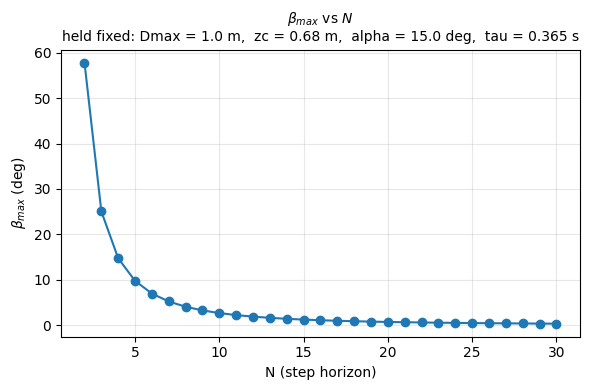

In [5]:
N_vals = np.arange(2, 31)
beta_vs_N = [beta_max(n, Dmax_ref, zc_ref, alpha_ref, tau_ref) for n in N_vals]

fixed_txt = fixed_values_text(Dmax=f"{Dmax_ref} m", zc=f"{zc_ref} m",
                               alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s")
print(fixed_txt)

plt.figure(figsize=(6, 4))
plt.plot(N_vals, beta_vs_N, 'o-', color='tab:blue')
plt.xlabel("N (step horizon)")
plt.ylabel(r"$\beta_{max}$ (deg)")
plt.title(r"$\beta_{max}$ vs $N$" + "\n" + fixed_txt, fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Sweep 2 of 5: $\beta_{max}$ vs $D_{max}$ (deviation budget)

**Varying:** $D_{max}$ from 0.1 m to 3.0 m.
**Held fixed:** $N=10$, $z_c=0.68$ m, $\alpha=15^\circ$, $\tau=0.365$ s.


held fixed: N = 10,  zc = 0.68 m,  alpha = 15.0 deg,  tau = 0.365 s


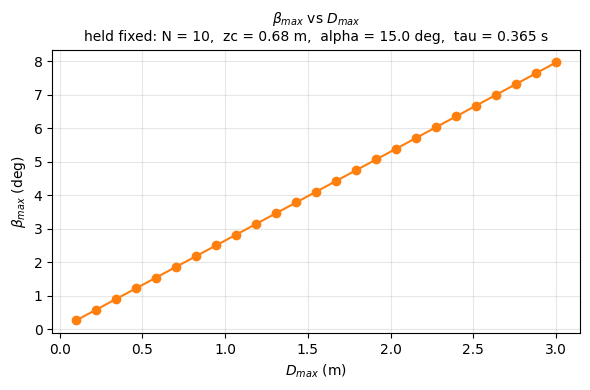

In [6]:
Dmax_vals = np.linspace(0.1, 3.0, 25)
beta_vs_Dmax = [beta_max(N_ref, d, zc_ref, alpha_ref, tau_ref) for d in Dmax_vals]

fixed_txt = fixed_values_text(N=N_ref, zc=f"{zc_ref} m",
                               alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s")
print(fixed_txt)

plt.figure(figsize=(6, 4))
plt.plot(Dmax_vals, beta_vs_Dmax, 'o-', color='tab:orange')
plt.xlabel(r"$D_{max}$ (m)")
plt.ylabel(r"$\beta_{max}$ (deg)")
plt.title(r"$\beta_{max}$ vs $D_{max}$" + "\n" + fixed_txt, fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Sweep 3 of 5: $\beta_{max}$ vs $z_c$ (CoM height)

**Varying:** $z_c$ from 0.3 m to 1.2 m.
**Held fixed:** $N=10$, $D_{max}=1.0$ m, $\alpha=15^\circ$, $\tau=0.365$ s.

Note $z_c$ enters both directly (linearly, in the denominator) and indirectly through
$\omega=\sqrt{g\cos\alpha/z_c}$ inside the $\cosh$ term -- the two effects partially
cancel, so this curve is noticeably flatter than the others.


held fixed: N = 10,  Dmax = 1.0 m,  alpha = 15.0 deg,  tau = 0.365 s


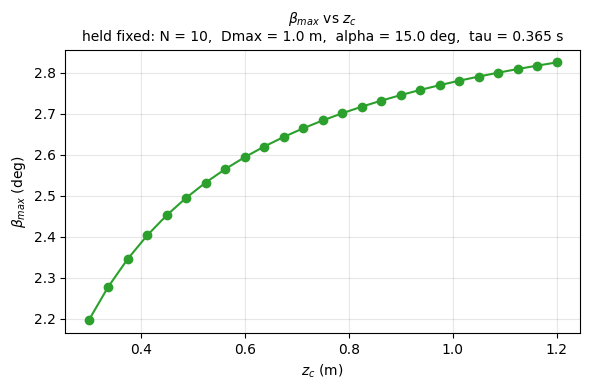

In [7]:
zc_vals = np.linspace(0.3, 1.2, 25)
beta_vs_zc = [beta_max(N_ref, Dmax_ref, z, alpha_ref, tau_ref) for z in zc_vals]

fixed_txt = fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                               alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s")
print(fixed_txt)

plt.figure(figsize=(6, 4))
plt.plot(zc_vals, beta_vs_zc, 'o-', color='tab:green')
plt.xlabel(r"$z_c$ (m)")
plt.ylabel(r"$\beta_{max}$ (deg)")
plt.title(r"$\beta_{max}$ vs $z_c$" + "\n" + fixed_txt, fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Sweep 4 of 5: $\beta_{max}$ vs $\alpha$ (incline angle)

**Varying:** $\alpha$ from 2$^\circ$ to 45$^\circ$.
**Held fixed:** $N=10$, $D_{max}=1.0$ m, $z_c=0.68$ m, $\tau=0.365$ s.


held fixed: N = 10,  Dmax = 1.0 m,  zc = 0.68 m,  tau = 0.365 s


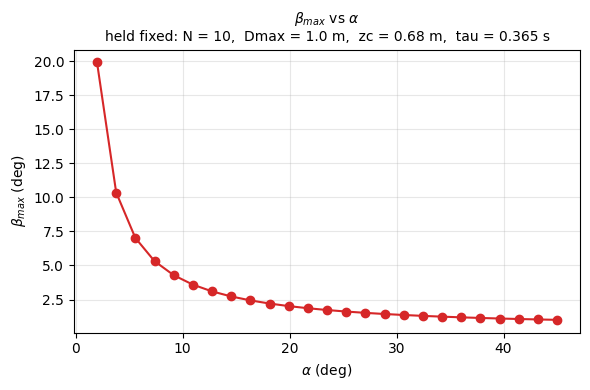

In [8]:
alpha_vals = np.linspace(2, 45, 25)
beta_vs_alpha = [beta_max(N_ref, Dmax_ref, zc_ref, a, tau_ref) for a in alpha_vals]

fixed_txt = fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                               zc=f"{zc_ref} m", tau=f"{tau_ref} s")
print(fixed_txt)

plt.figure(figsize=(6, 4))
plt.plot(alpha_vals, beta_vs_alpha, 'o-', color='tab:red')
plt.xlabel(r"$\alpha$ (deg)")
plt.ylabel(r"$\beta_{max}$ (deg)")
plt.title(r"$\beta_{max}$ vs $\alpha$" + "\n" + fixed_txt, fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Sweep 5 of 5: $\beta_{max}$ vs $\tau$ (single-support duration)

**Varying:** $\tau$ from 0.1 s to 0.7 s.
**Held fixed:** $N=10$, $D_{max}=1.0$ m, $z_c=0.68$ m, $\alpha=15^\circ$.

$\tau$ sits inside $\cosh(\omega\tau)$, so $\beta_{max}$ is far more sensitive to
$\tau$ than to any other parameter -- a longer stance phase causes the per-step
growth $\Delta L_0$ to blow up, crushing the allowable walking angle.


held fixed: N = 10,  Dmax = 1.0 m,  zc = 0.68 m,  alpha = 15.0 deg


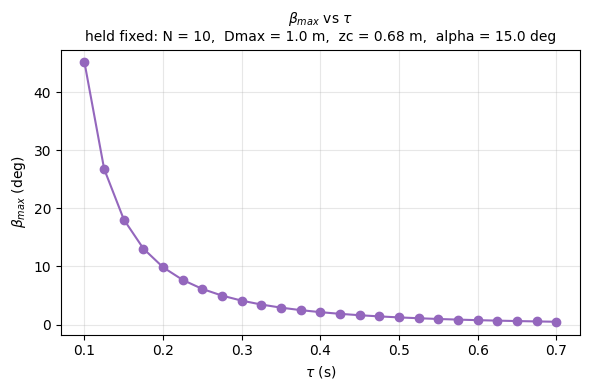

In [9]:
tau_vals = np.linspace(0.1, 0.7, 25)
beta_vs_tau = [beta_max(N_ref, Dmax_ref, zc_ref, alpha_ref, t) for t in tau_vals]

fixed_txt = fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                               zc=f"{zc_ref} m", alpha=f"{alpha_ref} deg")
print(fixed_txt)

plt.figure(figsize=(6, 4))
plt.plot(tau_vals, beta_vs_tau, 'o-', color='tab:purple')
plt.xlabel(r"$\tau$ (s)")
plt.ylabel(r"$\beta_{max}$ (deg)")
plt.title(r"$\beta_{max}$ vs $\tau$" + "\n" + fixed_txt, fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Combined overview

All five sweeps side by side, each panel's title repeating the fixed constants for
that sweep.


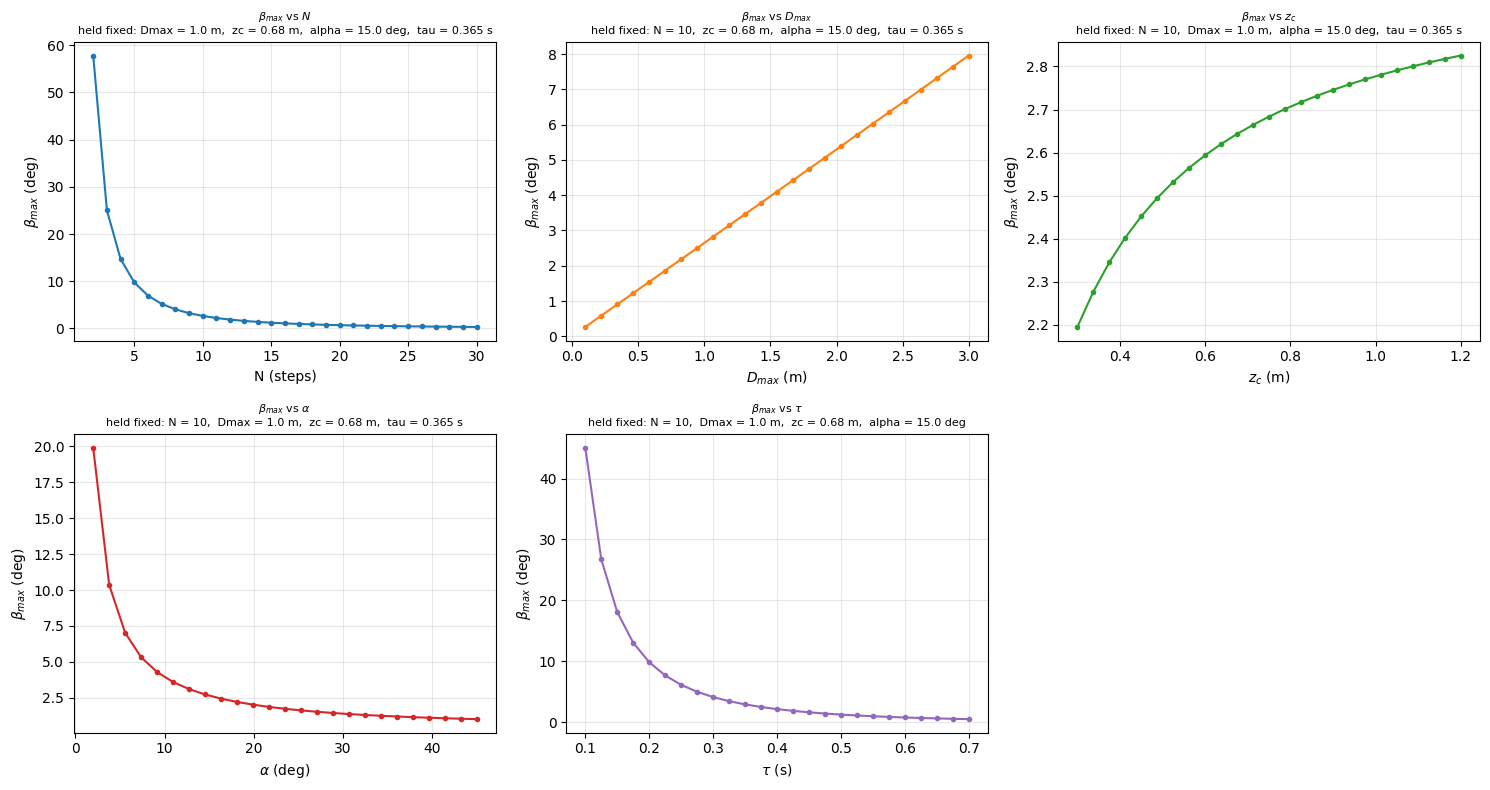

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sweeps = [
    (N_vals, beta_vs_N, "N (steps)", r"$\beta_{max}$ vs $N$",
     fixed_values_text(Dmax=f"{Dmax_ref} m", zc=f"{zc_ref} m",
                        alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s"), 'tab:blue'),
    (Dmax_vals, beta_vs_Dmax, r"$D_{max}$ (m)", r"$\beta_{max}$ vs $D_{max}$",
     fixed_values_text(N=N_ref, zc=f"{zc_ref} m",
                        alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s"), 'tab:orange'),
    (zc_vals, beta_vs_zc, r"$z_c$ (m)", r"$\beta_{max}$ vs $z_c$",
     fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                        alpha=f"{alpha_ref} deg", tau=f"{tau_ref} s"), 'tab:green'),
    (alpha_vals, beta_vs_alpha, r"$\alpha$ (deg)", r"$\beta_{max}$ vs $\alpha$",
     fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                        zc=f"{zc_ref} m", tau=f"{tau_ref} s"), 'tab:red'),
    (tau_vals, beta_vs_tau, r"$\tau$ (s)", r"$\beta_{max}$ vs $\tau$",
     fixed_values_text(N=N_ref, Dmax=f"{Dmax_ref} m",
                        zc=f"{zc_ref} m", alpha=f"{alpha_ref} deg"), 'tab:purple'),
]

for ax, (xv, yv, xlabel, title, fixed_txt, color) in zip(axes.flat, sweeps):
    ax.plot(xv, yv, 'o-', color=color, markersize=3)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\beta_{max}$ (deg)")
    ax.set_title(title + "\n" + fixed_txt, fontsize=8)
    ax.grid(alpha=0.3)

axes.flat[-1].axis('off')  # unused 6th panel
plt.tight_layout()
plt.show()


## Summary table

Reference-point value plus the min/max of $\beta_{max}$ attained within each sweep's
range (with the other four parameters held at their reference values).


In [11]:
summary_rows = [
    ("N", f"{N_vals.min()}-{N_vals.max()}", f"{min(beta_vs_N):.3f}", f"{max(beta_vs_N):.3f}"),
    ("Dmax [m]", f"{Dmax_vals.min():.2f}-{Dmax_vals.max():.2f}",
     f"{min(beta_vs_Dmax):.3f}", f"{max(beta_vs_Dmax):.3f}"),
    ("zc [m]", f"{zc_vals.min():.2f}-{zc_vals.max():.2f}",
     f"{min(beta_vs_zc):.3f}", f"{max(beta_vs_zc):.3f}"),
    ("alpha [deg]", f"{alpha_vals.min():.1f}-{alpha_vals.max():.1f}",
     f"{min(beta_vs_alpha):.3f}", f"{max(beta_vs_alpha):.3f}"),
    ("tau [s]", f"{tau_vals.min():.2f}-{tau_vals.max():.2f}",
     f"{min(beta_vs_tau):.3f}", f"{max(beta_vs_tau):.3f}"),
]

print(f"{'Variable':<12}{'Range swept':<16}{'min beta_max':<15}{'max beta_max':<15}")
print("-" * 58)
for row in summary_rows:
    print(f"{row[0]:<12}{row[1]:<16}{row[2]:<15}{row[3]:<15}")


Variable    Range swept     min beta_max   max beta_max   
----------------------------------------------------------
N           2-30            0.313          57.828         
Dmax [m]    0.10-3.00       0.265          7.962          
zc [m]      0.30-1.20       2.195          2.825          
alpha [deg] 2.0-45.0        1.008          19.915         
tau [s]     0.10-0.70       0.488          45.077         
